# UCI HAR : classification sur signal brut et features

on classe l'activite (6 classes : marche, montee, descente, assis, debout, couche). le decoupage d'UCI HAR separe deja les sujets (21 en train, 9 en test), donc source = sujets d'entrainement, cible = sujets de test.

In [11]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import predict, split_har, courbe_apprentissage, comparer_adapt, barres_adapt

## chargement

In [12]:
data_dir = "../../data/UCI HAR Dataset"

canaux = ["body_acc_x", "body_acc_y", "body_acc_z",
          "body_gyro_x", "body_gyro_y", "body_gyro_z",
          "total_acc_x", "total_acc_y", "total_acc_z"]

def charger(split):
    features = np.loadtxt(f"{data_dir}/{split}/X_{split}.txt")
    signaux = [np.loadtxt(f"{data_dir}/{split}/Inertial Signals/{c}_{split}.txt") for c in canaux]
    return np.hstack([features] + signaux)

Xs = charger("train")
ys = np.loadtxt(f"{data_dir}/train/y_train.txt").astype(int)
subj_s = np.loadtxt(f"{data_dir}/train/subject_train.txt").astype(int)

Xt = charger("test")
yt = np.loadtxt(f"{data_dir}/test/y_test.txt").astype(int)
subj_t = np.loadtxt(f"{data_dir}/test/subject_test.txt").astype(int)

noms_features = [l.split(" ", 1)[1] for l in open(f"{data_dir}/features.txt").read().strip().split("\n")]
noms_brut = [f"{c}_{i}" for c in canaux for i in range(128)]
noms_colonnes = noms_features + noms_brut
debut_brut = len(noms_features)

Xs.shape, Xt.shape, sorted(set(ys))

((7352, 1713),
 (2947, 1713),
 [np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4),
  np.int64(5),
  np.int64(6)])

## tableaux utilises

les colonnes 0 a 560 sont les features. les colonnes 561 a 1712 sont les echantillons bruts, les 128 instants de chaque canal mis bout a bout.

In [13]:
activites = dict(l.split() for l in open(f"{data_dir}/activity_labels.txt").read().strip().split("\n"))

resume = pd.DataFrame([
    ["Xs", Xs.shape, "561 features + 9 canaux x 128 echantillons, source (21 sujets)"],
    ["ys", ys.shape, "activite source"],
    ["subj_s", subj_s.shape, "sujet source"],
    ["Xt", Xt.shape, "561 features + 9 canaux x 128 echantillons, cible (9 sujets)"],
    ["yt", yt.shape, "activite cible"],
    ["subj_t", subj_t.shape, "sujet cible"],
], columns=["tableau", "dimensions", "contenu"])
print(resume.to_string(index=False))
print()
print("colonnes features :", 0, "a", debut_brut - 1, "  colonnes brutes :", debut_brut, "a", len(noms_colonnes) - 1)
print("activites :", activites)

tableau   dimensions                                                        contenu
     Xs (7352, 1713) 561 features + 9 canaux x 128 echantillons, source (21 sujets)
     ys      (7352,)                                                activite source
 subj_s      (7352,)                                                   sujet source
     Xt (2947, 1713)   561 features + 9 canaux x 128 echantillons, cible (9 sujets)
     yt      (2947,)                                                 activite cible
 subj_t      (2947,)                                                    sujet cible

colonnes features : 0 a 560   colonnes brutes : 561 a 1712
activites : {'1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS', '4': 'SITTING', '5': 'STANDING', '6': 'LAYING'}


In [14]:
apercu = pd.DataFrame(Xs[:5], columns=noms_colonnes)
apercu.insert(0, "activite", [activites[str(v)] for v in ys[:5]])
apercu.insert(0, "sujet", subj_s[:5])

with pd.option_context("display.max_columns", None):
    display(apercu)

sujet  activite  tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
0      1  STANDING           0.288585          -0.020294          -0.132905   
1      1  STANDING           0.278419          -0.016411          -0.123520   
2      1  STANDING           0.279653          -0.019467          -0.113462   
3      1  STANDING           0.279174          -0.026201          -0.123283   
4      1  STANDING           0.276629          -0.016570          -0.115362   

   tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  \
0         -0.995279         -0.983111         -0.913526         -0.995112   
1         -0.998245         -0.975300         -0.960322         -0.998807   
2         -0.995380         -0.967187         -0.978944         -0.996520   
3         -0.996091         -0.983403         -0.990675         -0.997099   
4         -0.998139         -0.980817         -0.990482         -0.998321   

   tBodyAcc-mad()-Y  tBodyAcc-mad()-Z  tBodyAcc-max()-X  tBodyAcc-max()-Y  \
0         -0.983185         -0.923527         -0.934724         -0.567378   
1         -0.974914         -0.957686         -0.943068         -0.557851   
2         -0.963668         -0.977469         -0.938692         -0.557851   
3         -0.982750         -0.989302         -0.938692         -0.576159   
4         -0.979672         -0.990441         -0.942469         -0.569174   

   tBodyAcc-max()-Z  tBodyAcc-min()-X  tBodyAcc-min()-Y  tBodyAcc-min()-Z  \
0         -0.744413          0.852947          0.685845          0.814263   
1         -0.818409          0.849308          0.685845          0.822637   
2         -0.818409          0.843609          0.682401          0.839344   
3         -0.829711          0.843609          0.682401          0.837869   
4         -0.824705          0.849095          0.683250          0.837869   

   tBodyAcc-sma()  tBodyAcc-energy()-X  tBodyAcc-energy()-Y  \
0       -0.965523            -0.999945            -0.999863   
1       -0.981930            -0.999991            -0.999788   
2       -0.983478            -0.999969            -0.999660   
3       -0.986093            -0.999976            -0.999736   
4       -0.992653            -0.999991            -0.999856   

   tBodyAcc-energy()-Z  tBodyAcc-iqr()-X  tBodyAcc-iqr()-Y  tBodyAcc-iqr()-Z  \
0            -0.994612         -0.994231         -0.987614         -0.943220   
1            -0.998405         -0.999150         -0.977866         -0.948225   
2            -0.999470         -0.997130         -0.964810         -0.974675   
3            -0.999504         -0.997180         -0.983799         -0.986007   
4            -0.999757         -0.998004         -0.981232         -0.991325   

   tBodyAcc-entropy()-X  tBodyAcc-entropy()-Y  tBodyAcc-entropy()-Z  \
0             -0.407747             -0.679338             -0.602122   
1             -0.714892             -0.500930             -0.570979   
2             -0.592235             -0.485821             -0.570979   
3             -0.627446             -0.850930             -0.911872   
4             -0.786553             -0.559477             -0.761434   

   tBodyAcc-arCoeff()-X,1  tBodyAcc-arCoeff()-X,2  tBodyAcc-arCoeff()-X,3  \
0                0.929294               -0.853011                0.359910   
1                0.611627               -0.329549                0.284213   
2                0.273025               -0.086309                0.337202   
3                0.061436                0.074840                0.198204   
4                0.313276               -0.131208                0.191161   

   tBodyAcc-arCoeff()-X,4  tBodyAcc-arCoeff()-Y,1  tBodyAcc-arCoeff()-Y,2  \
0               -0.058526                0.256892               -0.224848   
1                0.284595                0.115705               -0.090963   
2               -0.164739                0.017150               -0.074507   
3               -0.264307                0.072545               -0.155320   
4   

## 1. visualisation

on trace le premier canal brut (body_acc_x, les 128 colonnes qui suivent les features) pour deux activites : une marche et une debout.

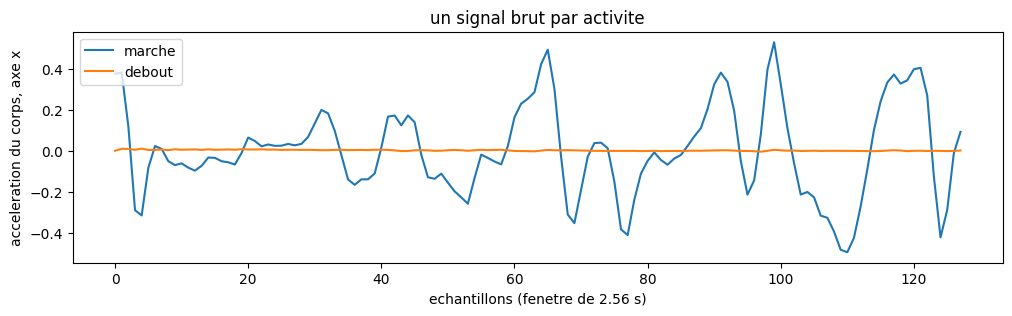

In [15]:
plt.figure(figsize=(12, 3))
for label, nom in [(1, "marche"), (5, "debout")]:
    idx = np.where(ys == label)[0][0]
    plt.plot(Xs[idx, debut_brut:debut_brut + 128], label=nom)
plt.xlabel("echantillons (fenetre de 2.56 s)")
plt.ylabel("acceleration du corps, axe x")
plt.title("un signal brut par activite")
plt.legend()
plt.show()

## 2. decoupage par sujet

les fenetres se recouvrent a 50 pourcent, donc deux fenetres voisines du meme sujet partagent des donnees.
on garde 4 sujets source pour le test source, et on separe les 9 sujets cible en 6 pour l'adaptation et 3 pour le test cible.

In [16]:
Xs_train, ys_train, Xs_test, ys_test, Xt_train, yt_train, Xt_test, yt_test = split_har(
    Xs, ys, subj_s, Xt, yt, subj_t)

len(Xs_train), len(Xs_test), len(Xt_train), len(Xt_test)

(5867, 1485, 1848, 1099)

## 3. source vers source et source vers cible

In [17]:
r_source_source = predict("classification", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("classification", Xs_train, ys_train, Xt_test, yt_test)
r_cible_cible = predict("classification", Xt_train, yt_train, Xt_test, yt_test)

print("source -> source :", round(r_source_source["accuracy"], 3))
print("source -> cible  :", round(r_source_cible["accuracy"], 3))
print("cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

source -> source : 0.958
source -> cible  : 0.957
cible  -> cible  : 0.872


## 4. combien de donnees cible pour un bon modele

on part du modele source, on ajoute des donnees cible a l'entrainement, et on mesure sur le test cible.

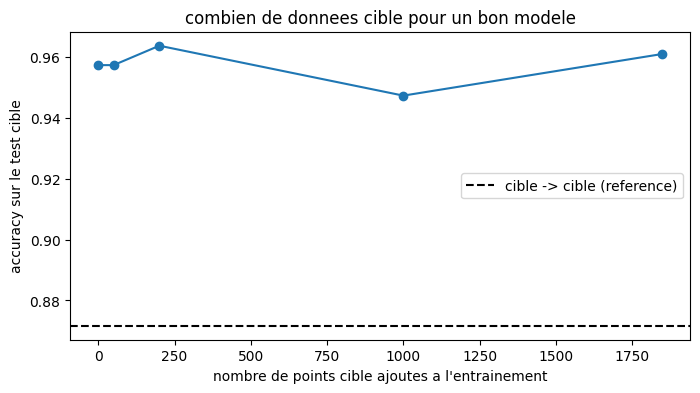

In [18]:
n_values = [0, 50, 200, 1000, len(Xt_train)]
acc_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xt_train[:n]])
        y_train = np.concatenate([ys_train, yt_train[:n]])
    acc_courbe.append(predict("classification", X_train, y_train, Xt_test, yt_test)["accuracy"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, acc_courbe, marker="o")
plt.axhline(r_cible_cible["accuracy"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("accuracy sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 5. courbes d'apprentissage separees (source et cible)

In [ ]:
n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848, 3000, len(Xs_train)]
ns_source, acc_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "classification", n_values)
ns_cible, acc_cible = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_transfert, acc_transfert = courbe_apprentissage(Xs_train, ys_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, acc_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, acc_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, acc_transfert, marker="o", label="transfert (train source -> test cible)")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage separees")
plt.legend()
plt.show()

## 6. equilibrage : autant de sujets en source qu'en cible


In [20]:
n_tirages = 5
rng = np.random.default_rng(0)
acc_ss, acc_sc = [], []

for k in range(n_tirages):
    tirage = list(rng.permutation(sorted(set(subj_s)))[:9])
    tr, te = tirage[:6], tirage[6:]
    Xa, ya = Xs[np.isin(subj_s, tr)], ys[np.isin(subj_s, tr)]
    Xb, yb = Xs[np.isin(subj_s, te)], ys[np.isin(subj_s, te)]
    a = predict("classification", Xa, ya, Xb, yb)["accuracy"]
    b = predict("classification", Xa, ya, Xt_test, yt_test)["accuracy"]
    acc_ss.append(a)
    acc_sc.append(b)
    print(f"tirage {k} : {len(Xa)} fenetres   source -> source {a:.3f}   source -> cible {b:.3f}")

print()
print(f"equilibre 9 vs 9, moyenne sur {n_tirages} tirages")
print("  source -> source :", round(float(np.mean(acc_ss)), 3))
print("  source -> cible  :", round(float(np.mean(acc_sc)), 3))
print("  cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

tirage 0 : 2160 fenetres   source -> source 0.928   source -> cible 0.923
tirage 1 : 1984 fenetres   source -> source 0.892   source -> cible 0.912
tirage 2 : 2043 fenetres   source -> source 0.864   source -> cible 0.920
tirage 3 : 2069 fenetres   source -> source 0.855   source -> cible 0.862
tirage 4 : 2052 fenetres   source -> source 0.852   source -> cible 0.898

equilibre 9 vs 9, moyenne sur 5 tirages
  source -> source : 0.878
  source -> cible  : 0.903
  cible  -> cible  : 0.872


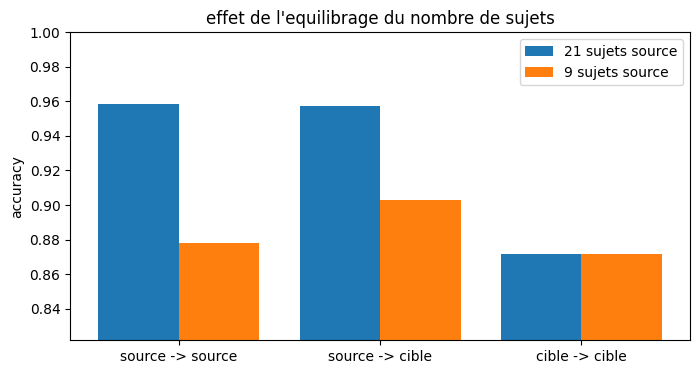

In [21]:
noms = ["source -> source", "source -> cible", "cible -> cible"]
desequilibre = [r_source_source["accuracy"], r_source_cible["accuracy"], r_cible_cible["accuracy"]]
equilibre = [float(np.mean(acc_ss)), float(np.mean(acc_sc)), r_cible_cible["accuracy"]]

x = np.arange(len(noms))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, desequilibre, 0.4, label="21 sujets source")
plt.bar(x + 0.2, equilibre, 0.4, label="9 sujets source")
plt.xticks(x, noms)
plt.ylim(max(0.0, min(desequilibre + equilibre) - 0.05), 1.0)
plt.ylabel("accuracy")
plt.title("effet de l'equilibrage du nombre de sujets")
plt.legend()
plt.show()

## 7. adaptation de domaine (ADAPT)

feature_based,  CORAL

instance_based,  KMM

parameter_based,  RegularTransferLC

(1848, 6)
sans adaptation                  0.975
CORAL (feature)                  0.776
KMM (instance)                   0.957
RegularTransferLC (parametre)    0.936
cible -> cible                   0.93


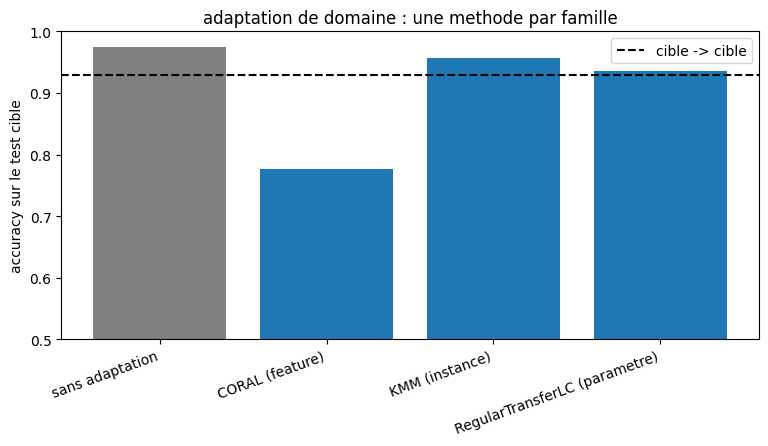

In [22]:
resultats = comparer_adapt("classification", Xs_train, ys_train, Xt_train, yt_train, Xt_test, yt_test)

for k, v in resultats.items():
    print(f"{k:32s} {round(v, 3)}")

barres_adapt(resultats, "adaptation de domaine : une methode par famille","accuracy sur le test cible", ylim=(0.5, 1.0))